# Laboratory Exercise 2: Mobile Plans

Telekomuna is a mobile operator in Macedonia. Its export in `data/customers.csv` holds one row per customer who signed a postpaid contract, and `data/daily-activations.csv` counts the contracts activated on each day. The customers are synthetic and describe no real person or operator, and the device models are invented.

The columns of `customers.csv` are these:

- `customer_id`, the identifier of the customer, and `signed_on`, the day the contract was signed,
- `device_model`, the model of the customer's phone, and `origin`, which is a new number, a number ported from another operator, or an upgrade,
- `contract`, a personal or a business contract, and `lines`, the number of SIM cards on the contract, as the system recorded it,
- `package`, one of small, medium, large, extra large, and unlimited,
- `payment`, the way the customer pays, and `handset`, a phone financed by the operator or the customer's own device, with `instalment`, the monthly instalment for the phone in denars,
- `calls`, the calls in the first month, and `call_minutes`, the minutes of those calls,
- `data_gb`, the mobile data used in the first month in gigabytes, `deposit`, the deposit in denars that a credit check set at signing, and `sms`, the text messages sent in the first month, and
- `monthly_bill`, the bill of the first month in denars, which a later model will predict.

The customers are to be prepared for that model: every gap filled for a reason, every unusual value understood, every label turned into numbers, and every column brought to a comparable scale, with every step learned from the training customers alone. No request asks for a model.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, MissingIndicator, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer, RobustScaler,
                                   StandardScaler)

DATA = Path("data")
# Every random step uses this seed, so a rerun gives the same result.
SEED = 2026

In [2]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [3]:
class FrequencyEncoder(TransformerMixin, BaseEstimator):
    """Replaces each category with its share of the rows passed to fit, and an unseen category with 0."""

    def fit(self, X: pd.DataFrame, y: object = None) -> "FrequencyEncoder":
        self.shares_ = {column: X[column].value_counts(normalize=True) for column in X.columns}
        return self

    def transform(self, X: pd.DataFrame) -> np.ndarray:
        return np.column_stack([X[column].map(share).fillna(0).to_numpy(dtype=float)
                                for column, share in self.shares_.items()])

    def get_feature_names_out(self, input_features: object = None) -> np.ndarray:
        return np.array([f"{column}_frequency" for column in self.shares_])

In [4]:
customers = pd.read_csv(DATA / "customers.csv")
daily_activations = pd.read_csv(DATA / "daily-activations.csv")
customers.head()

,customer_id,signed_on,device_model,contract,origin,package,payment,handset,calls,call_minutes,data_gb,lines,instalment,deposit,sms,monthly_bill
0,91001,2024-12-03,Kestrel A3,personal,new number,small,direct debit,financed,28,93,18.5,2,450,7850,8,1000
1,91002,2024-12-03,Aster 12,personal,new number,medium,card,financed,24,76,11.5,2,450,860,10,1174
2,91003,2024-12-05,Terra 6,personal,new number,extra large,direct debit,financed,148,449,9.7,1,450,2330,28,1627
3,91004,2024-12-06,Lumo 4,personal,upgrade,small,bank transfer,financed,100,294,4.3,1,450,1850,30,x
4,91005,2024-12-06,Lark 21,personal,new number,extra large,cash,financed,59,165,9.7,1,900,1450,7,2019


## Task 1: The Gaps

### 1.1 Reading the Gaps

The file writes a value it does not have with a marker of its own. Read the customers into a table named `df` in which every such value is missing. Count the missing values in each column, and show where they fall.

missing[missing > 0] 
 payment         22
call_minutes    77
data_gb         19
instalment      41
monthly_bill     8
dtype: int64


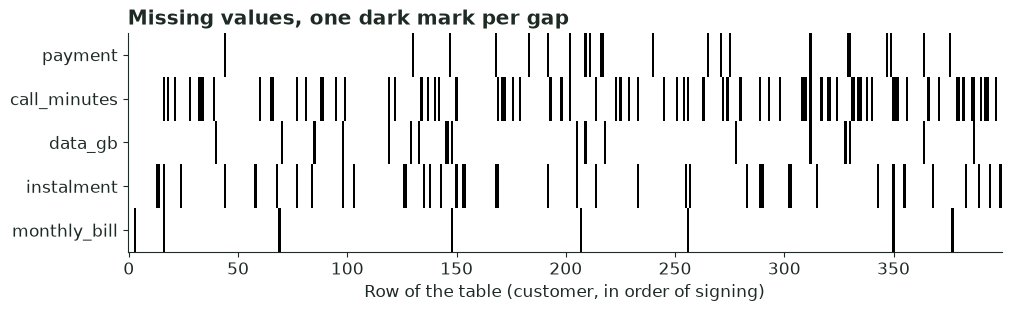

In [23]:
# Write your solution here.
# 03-data-preparation §1 (The Table): the file writes a value it does not have as "x", so read_csv takes
# na_values="x". Without it, every column that holds an "x" would be read as text instead of numbers.
df = pd.read_csv(DATA / "customers.csv", na_values="x")

# 03-data-preparation §2 (Discovering Missing Values): count the gaps per column, keep the columns that have any.
missing = df.isna().sum()
print("missing[missing > 0] \n", missing[missing > 0])

# 03-data-preparation §2: draw the gaps row by row (one dark mark per missing value), so their pattern shows.
# The rows are in the order of signing, so the picture also shows that the gaps are spread over the whole period.
gaps = df.columns[df.isna().any()]
fig, ax = plt.subplots(figsize=(10, 3))
ax.imshow(df[gaps].isna().T, aspect="auto", interpolation="none", cmap="Greys")
ax.set(yticks=range(len(gaps)), yticklabels=gaps, xlabel="Row of the table (customer, in order of signing)",
       title="Missing values, one dark mark per gap")
ax.grid(False)
plt.show()

### 1.2 Why Values Are Missing

For each column with missing values, find out whether its gaps depend on another column, whether a gap means that the value does not exist, or whether the gaps follow no pattern. Show the comparison that decides each case.

In [24]:
# Write your solution here.
# 01-data-gathering §10 (The Shape of the Missingness): cross a column with gaps against a candidate cause.
# instalment against handset: a customer who brings their own device has no phone to pay off.
print(pd.crosstab(df["handset"], df["instalment"].isna().rename("instalment missing")), end="\n\n")

# 02-statistical-inference §8 (The Chi-Squared Tests): chi2_contingency tests every gap column against every label.
# H0: whether the value is missing is independent of the label. A p-value below 0.05 means the gap depends on it.
labels = ["contract", "origin", "package", "handset", "payment"]
p_values = pd.DataFrame({
    column: {label: stats.chi2_contingency(pd.crosstab(df[label], df[column].isna())).pvalue
             for label in labels if label != column}
    for column in ["call_minutes", "data_gb", "payment"]
})
print(p_values.round(4), end="\n\n")

# 01-data-gathering §10 (groupby + agg with sum/size/mean): the share of missing minutes per origin is the
# comparison that decides call_minutes.
# Decisions:
# - instalment: missing for all 41 own-device customers and for none with a financed phone, so a gap means the
#   value does not exist (there is no instalment).
# - call_minutes: missing for 42 % of ported customers against 4 % and 7 % of the others (chi-squared p < 0.0001),
#   so its gaps depend on origin (missing at random, MAR, 03-data-preparation §3).
# - data_gb and payment: no label has p < 0.05, so their gaps follow no pattern we can see (treated as MCAR).
df["call_minutes"].isna().groupby(df["origin"]).agg(["sum", "size", "mean"]).round(2)

instalment missing  False  True 
handset                         
financed              359      0
own device              0     41

          call_minutes  data_gb  payment
contract        0.7959   0.7926   0.7075
origin          0.0000   0.2924   0.5041
package         0.3751   0.5222   0.7817
handset         1.0000   1.0000   0.8594
payment         0.9468   0.9175      NaN



,sum,size,mean
origin,,,
new number,6,141,0.04
ported,63,151,0.42
upgrade,8,108,0.07


### 1.3 What Deleting Would Cost

Find out how many customers would remain if every customer with a missing value were dropped, and how the mix of origins would change. Then decide what to do with the customers that state no monthly bill, and apply the decision to `df`.

In [7]:
# Write your solution here.
# 03-data-preparation §4 (Deletion or Imputation): dropna() drops every customer with any gap.
complete = df.dropna()
print(len(df), "customers, of whom", len(complete), "have no gap at all")

# 01-data-gathering §14 (Counts of a Category): value_counts(normalize=True) gives the share of each origin,
# compared before and after the drop.
print(pd.DataFrame({"all customers": df["origin"].value_counts(normalize=True),
                    "complete customers": complete["origin"].value_counts(normalize=True)}).round(3))
# Deleting would keep 258 of 400 customers and change who is represented: ported customers fall from 38 % to
# 28 % (their minutes are often missing), and every own-device customer disappears (they have no instalment).
# So deletion is rejected, and the gaps are filled in Task 2.

# 03-data-preparation §4: a customer without the response (monthly_bill) can neither train nor test a model of
# the bill, so these 8 customers are the only rows that are dropped.
df = df.dropna(subset=["monthly_bill"]).reset_index(drop=True)
len(df)

400 customers, of whom 258 have no gap at all
            all customers  complete customers
origin                                       
new number          0.352               0.415
ported              0.378               0.279
upgrade             0.270               0.306


392

## Task 2: The Split and the Fills

### 2.1 The Test Customers

The customers who signed on 1 September 2025 or later stand in for customers that the preparation has never seen. Set them aside as the test customers, `X_test` and `y_test`, and keep the earlier customers as the training customers, `X_train` and `y_train`, where `X` holds every column except the monthly bill and `y` holds the monthly bill. Every later step learns only from the training customers. Report the number of each.

In [8]:
# Write your solution here.
# 03-data-preparation §5 (The Split Comes First): X holds every column except the response, y holds the response.
X, y = df.drop(columns="monthly_bill"), df["monthly_bill"]

# Unlike the random train_test_split of 03-data-preparation §5, the task splits by date: customers who signed on
# 1 September 2025 or later stand in for customers the preparation has never seen. Dates written as
# YYYY-MM-DD compare correctly as text, and the same mask selects the matching rows of X and y.
test = df["signed_on"] >= "2025-09-01"
X_train, X_test, y_train, y_test = X[~test], X[test], y[~test], y[test]
len(X_train), len(X_test)

(294, 98)

### 2.2 Filling the Gaps

Fill the gaps of each column in the way its pattern calls for, learning every fill from the training customers, and keep a record of the filled values wherever the absence itself carries information. Report the value that each fill by a single value uses.

In [9]:
# Write your solution here.
# 03-data-preparation §6 (Imputation): one imputer per gap pattern found in 1.2, joined with the ColumnTransformer
# of 03-data-preparation §11.
# - instalment does not exist for an own device, so SimpleImputer fills the constant 0 (no instalment is paid).
# - call_minutes depends on origin (MAR), so IterativeImputer predicts it from the calls, and add_indicator=True
#   (03-data-preparation §6, MissingIndicator) keeps a flag, because the absence itself marks mostly ported customers.
# - data_gb and payment follow no pattern, so the median and the most frequent value fill them.
fills = ColumnTransformer([
    ("instalment", SimpleImputer(strategy="constant", fill_value=0), ["instalment"]),
    ("minutes", IterativeImputer(max_iter=20, random_state=SEED, add_indicator=True), ["calls", "call_minutes"]),
    ("data", SimpleImputer(strategy="median"), ["data_gb"]),
    ("payment", SimpleImputer(strategy="most_frequent"), ["payment"]),
]).set_output(transform="pandas")

# 03-data-preparation §5: every fill is learned from the training customers and only applied to the test customers.
filled_train, filled_test = fills.fit_transform(X_train), fills.transform(X_test)

# 03-data-preparation §6: statistics_ holds the single value a SimpleImputer fills with.
# instalment is filled with 0, data_gb with its training median of 8.7 GB, payment with "direct debit".
print({name: fills.named_transformers_[name].statistics_[0] for name in ["instalment", "data", "payment"]})
filled_train.isna().sum().sum(), filled_test.isna().sum().sum(), list(filled_train.columns)

{'instalment': 0, 'data': np.float64(8.7), 'payment': 'direct debit'}


(np.int64(0),
 np.int64(0),
 ['instalment__instalment',
  'minutes__calls',
  'minutes__call_minutes',
  'minutes__missingindicator_call_minutes',
  'data__data_gb',
  'payment__payment'])

### 2.3 How Well a Fill Recovers the Minutes

Hide the known call minutes of every training customer whose identifier is divisible by five. Fill these minutes back in three ways, all from the numeric columns: with the median minutes, from the five most similar customers judged on standardized columns, and by predicting each column from the others in rounds with the seed 2026. Measure how far each fill lies from the true minutes on average, and show the filled minutes against the true ones.

46 minutes hidden; mean absolute error of each fill:
median                  91.3
5 nearest neighbours    44.9
iterative               24.7
dtype: float64


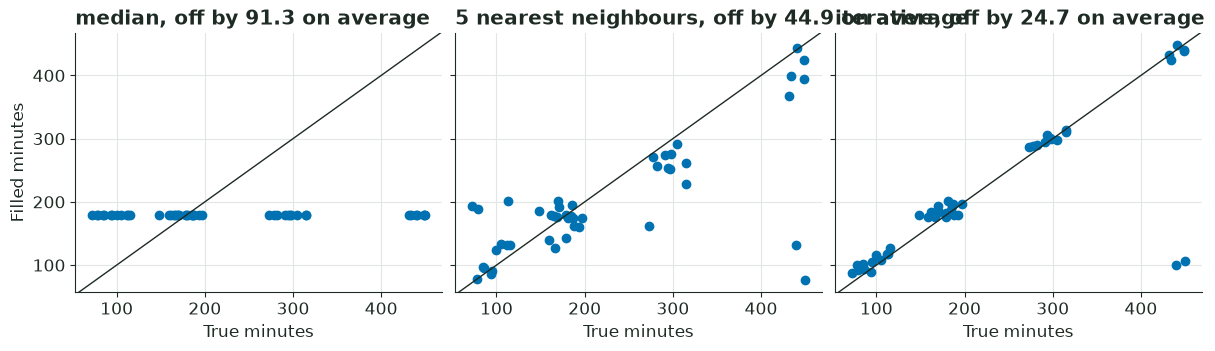

In [10]:
# Write your solution here.
# 03-data-preparation §6: hide known values, fill them back in, and compare with the truth by the mean absolute
# difference. Here: the known minutes of every training customer whose identifier is divisible by five.
numeric = ["calls", "call_minutes", "data_gb", "lines", "instalment", "deposit", "sms"]
known = X_train.dropna(subset=["call_minutes"])
mask = (known["customer_id"] % 5 == 0).to_numpy()
masked = known[numeric].copy()
masked.loc[mask, "call_minutes"] = np.nan
column = numeric.index("call_minutes")
truth = known.loc[mask, "call_minutes"].to_numpy()


def impute_scaled(imputer: KNNImputer, frame: pd.DataFrame) -> np.ndarray:
    # 03-data-preparation §6: distances need comparable units, so the neighbours are found on standardized columns.
    scaler = StandardScaler().fit(frame)
    return scaler.inverse_transform(imputer.fit_transform(scaler.transform(frame)))


# 03-data-preparation §6: the median, the five most similar customers, and predicting each column from the others
# in rounds (IterativeImputer) with the seed 2026.
filled = {
    "median": SimpleImputer(strategy="median").fit_transform(masked),
    "5 nearest neighbours": impute_scaled(KNNImputer(n_neighbors=5), masked),
    "iterative": IterativeImputer(max_iter=20, random_state=SEED).fit_transform(masked),
}
errors = pd.Series({name: np.abs(truth - values[mask, column]).mean() for name, values in filled.items()})
print(len(truth), "minutes hidden; mean absolute error of each fill:")
print(errors.round(1))

# 03-data-preparation §6 (plot): filled minutes against the true ones; the diagonal is a perfect fill.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, name in zip(axes, filled):
    ax.scatter(truth, filled[name][mask, column], color=PALETTE[0])
    ax.axline((100, 100), slope=1, color=INK, linewidth=1)
    ax.set(title=f"{name}, off by {errors[name]:.1f} on average", xlabel="True minutes")
axes[0].set_ylabel("Filled minutes")
plt.show()
# The median gives every hidden customer the same minutes, so its error is as large as the spread of the column.
# The minutes are about three times the calls, so the model-based fills, which use the calls, are far closer;
# the iterative fill is the closest, which supports the choice of IterativeImputer in 2.2.

### 2.4 Gaps in Time

`daily_activations` counts the contracts activated on each day, and a day without a row was not recorded. Make every day of the period visible, then fill each gap from the neighbouring days, at most three days into a gap and only between recorded days. Report how many days are missing before the fill and how many stay missing after it, and show the series around its longest gap.

days missing before the fill: 26 | still missing after it: 10
longest gap: 2025-05-18 to 2025-05-30 (13 days)


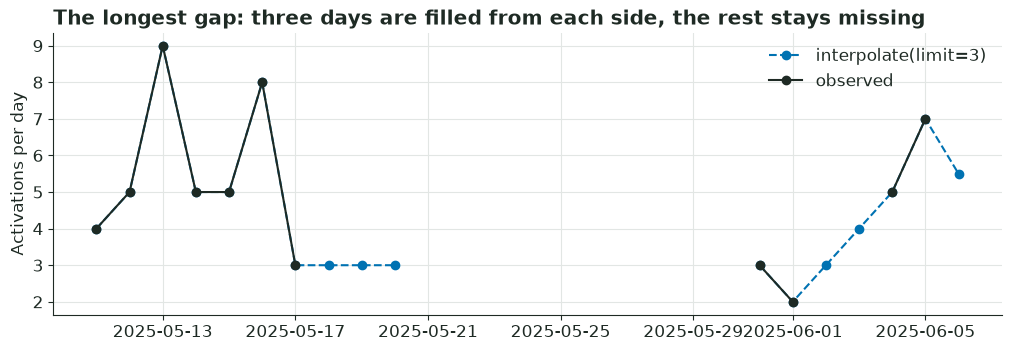

In [11]:
# Write your solution here.
# 03-data-preparation §7 (Interpolation): a date index plus asfreq("D") adds a row, with a gap, for every day
# that has no row, which makes every unrecorded day visible.
activations = daily_activations.set_index(pd.to_datetime(daily_activations["date"]))["activations"].asfreq("D")
gap = activations.isna()

# 03-data-preparation §7: limit=3 fills at most three days into a gap, limit_area="inside" only between recorded days.
filled_days = activations.interpolate(method="time", limit=3, limit_area="inside")
print("days missing before the fill:", gap.sum(), "| still missing after it:", filled_days.isna().sum())

# Not from the auditory exercises: number the runs of consecutive missing days to find the longest gap.
runs = (gap != gap.shift()).cumsum()[gap]
longest = runs[runs == runs.value_counts().idxmax()].index
window = slice(longest[0] - pd.Timedelta(days=7), longest[-1] + pd.Timedelta(days=7))
print("longest gap:", longest[0].date(), "to", longest[-1].date(), f"({len(longest)} days)")

# 03-data-preparation §7 (plot): the filled series dashed under the observed one, around the longest gap.
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(filled_days[window], color=PALETTE[0], linestyle="--", marker="o", label="interpolate(limit=3)")
ax.plot(activations[window], color=INK, marker="o", label="observed")
ax.set(ylabel="Activations per day", title="The longest gap: three days are filled from each side, the rest stays missing")
ax.legend()
plt.show()
# The fill only goes three days into the 13-day gap, so 10 days stay missing instead of being invented.

## Task 3: Outliers

### 3.1 Unusual Numbers of Lines

Flag the unusual numbers of lines among the training customers in two ways: as more than 1.5 interquartile ranges beyond the quartiles, and as more than three standard deviations from the mean. Report how many customers each way flags, show them, and explain why the two ways disagree.

In [12]:
# Write your solution here.
# 03-data-preparation §8 (Outliers): the IQR rule flags a value more than 1.5 IQR beyond the quartiles,
# the z-score rule a value more than three standard deviations from the mean.
def iqr_outliers(values: pd.Series) -> pd.Series:
    q1, q3 = values.quantile([0.25, 0.75])
    return (values < q1 - 1.5 * (q3 - q1)) | (values > q3 + 1.5 * (q3 - q1))


lines = X_train["lines"]
flagged = iqr_outliers(lines)
z_flagged = pd.Series(np.abs(stats.zscore(lines)) > 3, index=lines.index)
print("IQR rule flags", flagged.sum(), "| three standard deviations flag", z_flagged.sum())

# 03-data-preparation §8 (crosstab of the flags): show the flagged customers with their contract.
# The rules disagree: the quartiles are 1 and 3 lines, so the IQR fence lies at 6 and flags every business contract
# as well. The four values of 100 and 200 lines inflate the standard deviation to about 16, so the z-score fence lies
# above 50 and flags only those four, just as the diesel cars of 03-data-preparation §8 inflate the spread.
both_rules = flagged | z_flagged
X_train.loc[both_rules, ["customer_id", "contract", "lines"]].assign(
    iqr_rule=flagged[both_rules], z_rule=z_flagged[both_rules]).sort_values("lines")

IQR rule flags 16 | three standard deviations flag 4


,customer_id,contract,lines,iqr_rule,z_rule
290,91297,business,10,True,False
117,91121,business,16,True,False
176,91181,business,18,True,False
240,91246,business,20,True,False
189,91194,business,22,True,False
55,91058,business,22,True,False
219,91225,business,23,True,False
105,91109,business,26,True,False
118,91122,business,30,True,False
27,91030,business,34,True,False


### 3.2 Errors or Genuine Values

Decide for each flagged number of lines whether it is an error or a genuine value, and handle it accordingly in `X`, `X_train`, and `X_test`.

In [13]:
# Write your solution here.
# 03-data-preparation §8: "an outlier is removed only when it is an error, and otherwise it is kept".
# - Business contracts hold 10 to 38 lines: a company with many SIM cards is plausible, so they are genuine and kept.
# - Personal contracts hold 1 to 4 lines, then jump to 100 and 200: no person has that many SIM cards, so these are
#   recording errors. They become missing values and are filled with the median in the pipeline of 5.1.
def fix_lines(frame: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    errors = (frame["contract"] == "personal") & (frame["lines"] > 4)
    # Series.mask replaces the values where the condition holds with NaN (the column becomes float, so NaN fits).
    return frame.assign(lines=frame["lines"].mask(errors)), int(errors.sum())


# The same rule is applied to X, X_train and X_test, so every table holds the same corrected values.
X, errors_all = fix_lines(X)
X_train, errors_train = fix_lines(X_train)
X_test, errors_test = fix_lines(X_test)
errors_all, errors_train, errors_test

(4, 4, 0)

### 3.3 Unusual Combinations

Among the training personal customers with known calls and call minutes, find the customers whose combination of calls and minutes is unusual, in two ways: by how quickly random splits isolate a customer, and by how much sparser its neighbourhood is than the neighbourhoods of its neighbours. Judge both on the two columns standardized, treat 2% of the customers as unusual, use 20 neighbours, and use the seed 2026. Decide what to do with the customers that both ways flag.

Isolation Forest flags 5 | Local Outlier Factor flags 5 | both 4


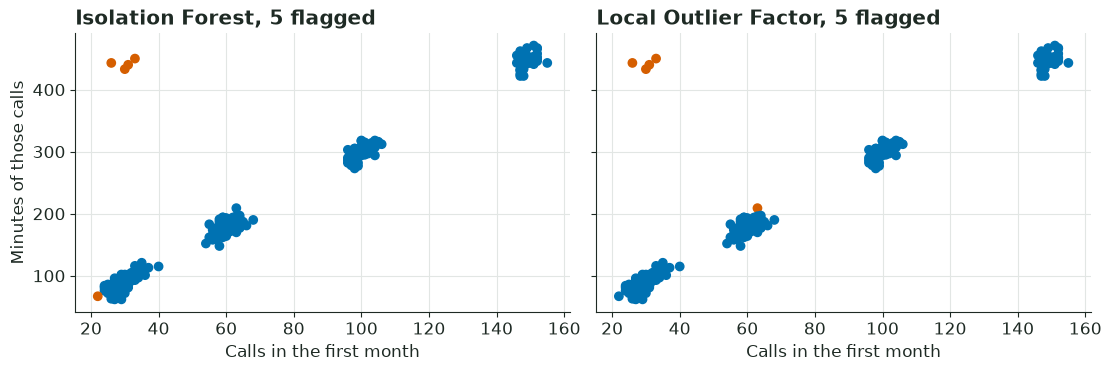

,customer_id,calls,call_minutes,minutes_per_call,forest,lof
56,91059,63,209.0,3.3,False,True
77,91081,22,67.0,3.0,True,False
97,91101,26,443.0,17.0,True,True
128,91132,30,433.0,14.4,True,True
263,91270,33,450.0,13.6,True,True
288,91295,31,440.0,14.2,True,True


In [14]:
# Write your solution here.
# 03-data-preparation §8: IsolationForest isolates a row with random splits, LocalOutlierFactor compares the density
# of a row's neighbourhood with that of its neighbours. Both on the two columns standardized, 2 % contamination.
personal = X_train[(X_train["contract"] == "personal") & X_train["call_minutes"].notna()]
pair = StandardScaler().fit_transform(personal[["calls", "call_minutes"]])
forest = IsolationForest(contamination=0.02, random_state=SEED).fit_predict(pair) == -1
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02).fit_predict(pair) == -1
print("Isolation Forest flags", forest.sum(), "| Local Outlier Factor flags", lof.sum(), "| both", (forest & lof).sum())

# 03-data-preparation §8 (plot): the flagged customers in red.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, flags, name in [(axes[0], forest, "Isolation Forest"), (axes[1], lof, "Local Outlier Factor")]:
    ax.scatter(personal["calls"], personal["call_minutes"], c=np.where(flags, PALETTE[1], PALETTE[0]))
    ax.set(title=f"{name}, {flags.sum()} flagged", xlabel="Calls in the first month")
axes[0].set_ylabel("Minutes of those calls")
plt.show()

# Decision (03-data-preparation §8: remove only errors): every other personal customer talks 2.1 to 3.3 minutes per
# call, while the four customers both methods flag talk 13.6 to 17 minutes per call, with a normal number of calls.
# Each value alone lies in the normal range, but the combination is implausible, so their minutes are treated as a
# recording error: they become missing values, and the iterative fill of 2.2 predicts them from the calls.
both = personal.index[forest & lof]
X.loc[both, "call_minutes"] = np.nan
X_train.loc[both, "call_minutes"] = np.nan

# Not from the auditory exercises: minutes per call shows why the combination is unusual.
personal.loc[forest | lof, ["customer_id", "calls", "call_minutes"]].assign(
    minutes_per_call=lambda t: (t["call_minutes"] / t["calls"]).round(1),
    forest=forest[forest | lof], lof=lof[forest | lof])

### 3.4 Capping the Data

Find the 1st and the 99th percentiles of the data used among the training customers, and count the test customers that lie beyond them. Decide whether to cap the data at these bounds.

In [15]:
# Write your solution here.
# 03-data-preparation §8 (capping): the bounds are the 1st and 99th percentiles of the training customers, and the
# same bounds are applied to the test customers.
low, high = X_train["data_gb"].quantile([0.01, 0.99])
beyond = (X_test["data_gb"] < low) | (X_test["data_gb"] > high)
print(f"training bounds: {low:.2f} GB and {high:.2f} GB; test customers beyond them: {beyond.sum()}")

# Decision: no capping. Every test customer beyond the bounds uses 78 to 94 GB, more than three times the largest
# training value (27.5 GB), and all of them hold the Lumo 5 or the Kestrel A4, two models only the test customers
# have. Their values are consistent with each other, so they describe new heavy users, not errors. Capping them at
# 23 GB would record them as ordinary customers (03-data-preparation §8: capping suits values believed to be wrong).
# The long tail is reduced instead by the power transform of 4.2.
X_test.loc[beyond, ["customer_id", "signed_on", "device_model", "package", "data_gb"]]

training bounds: 2.68 GB and 23.02 GB; test customers beyond them: 6


,customer_id,signed_on,device_model,package,data_gb
303,91310,2025-09-05,Lumo 5,medium,90.4
308,91315,2025-09-10,Kestrel A4,medium,89.6
320,91327,2025-09-27,Kestrel A4,large,83.7
330,91337,2025-10-10,Lumo 5,medium,92.5
340,91347,2025-10-20,Kestrel A4,extra large,94.1
359,91367,2025-11-07,Lumo 5,small,78.2


## Task 4: Encoding and Scaling

### 4.1 Labels as Numbers

Turn every label into numbers in the way its kind calls for, learning from the training customers:

- the package keeps its order, from small to unlimited,
- a label without an order gets one column per category, a single column when it has two categories, and zeros for a category that the training customers never held, and
- the device model becomes its share of the training customers, with 0 for a model that the training customers never held.

Report the code of each package, the number of columns that the labels without an order become, and the share of the Lumo 4.

In [16]:
# Write your solution here.
# 03-data-preparation §9 (Encoding):
# - the package is ordinal, so OrdinalEncoder gets its order explicitly (otherwise it sorts alphabetically),
package_order = [["small", "medium", "large", "extra large", "unlimited"]]
ordinal = OrdinalEncoder(categories=package_order).fit(X_train[["package"]])
codes = ordinal.transform(pd.DataFrame({"package": package_order[0]})).ravel()
print("package codes:", dict(zip(package_order[0], codes)))

# - labels without an order get one-hot columns; drop="if_binary" keeps one column for two categories (contract,
#   handset), handle_unknown="ignore" gives zeros for a category the training customers never held. The payment gaps
#   are filled first with the most frequent value, as decided in 2.2 (make_pipeline: 03-data-preparation §11).
nominal = ["contract", "origin", "payment", "handset"]
one_hot = make_pipeline(SimpleImputer(strategy="most_frequent"),
                        OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)).fit(X_train[nominal])
print(len(one_hot.get_feature_names_out()), "one-hot columns:", list(one_hot.get_feature_names_out()))

# - the device model has many values, so the FrequencyEncoder of the setup (03-data-preparation §9) replaces it with
#   its share of the training customers; a model the training customers never held becomes 0.
frequency = FrequencyEncoder().fit(X_train[["device_model"]])
print("share of the Lumo 4:", round(frequency.shares_["device_model"]["Lumo 4"], 4))

package codes: {'small': np.float64(0.0), 'medium': np.float64(1.0), 'large': np.float64(2.0), 'extra large': np.float64(3.0), 'unlimited': np.float64(4.0)}
9 one-hot columns: ['contract_personal', 'origin_new number', 'origin_ported', 'origin_upgrade', 'payment_bank transfer', 'payment_card', 'payment_cash', 'payment_direct debit', 'handset_own device']
share of the Lumo 4: 0.2313


### 4.2 Comparable Scales

Bring every numeric column to a scale that suits it, and reduce the skew of the columns with a long right tail. Report the skew of the deposit before and after, the power that brings it closest to a normal distribution, and what the text messages need instead.

deposit: skew 2.15 before, -0.00 after, lambda 0.029 (close to 0, which means the logarithm)
text messages equal to 0 among the training customers: 45


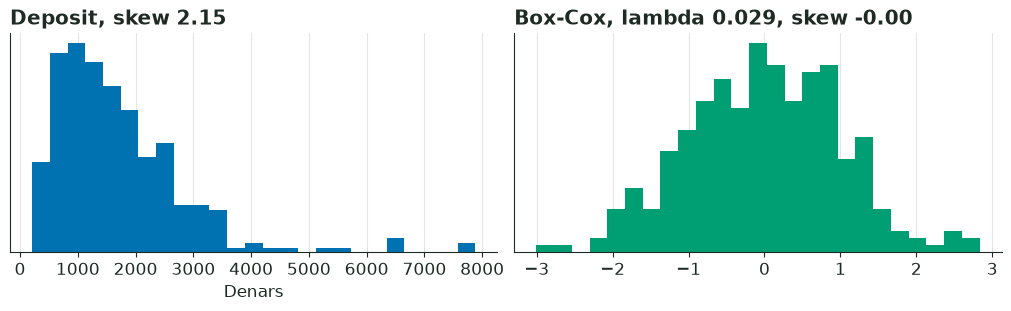

,scale,skew before,skew after
calls,StandardScaler,0.84,0.84
call_minutes,StandardScaler,0.77,0.77
instalment,StandardScaler,0.46,0.46
lines,PowerTransformer (box-cox),5.03,0.27
data_gb,PowerTransformer (box-cox),1.06,-0.00
deposit,PowerTransformer (box-cox),2.16,-0.00
sms,PowerTransformer (yeo-johnson),1.58,-0.06


In [17]:
# Write your solution here.
# 03-data-preparation §10 (Scaling and Power Transforms): Box-Cox finds the power lambda that makes a column closest
# to normal; it needs positive values. The deposit is positive and skewed to the right.
box_cox = PowerTransformer(method="box-cox").fit(X_train[["deposit"]])
transformed = box_cox.transform(X_train[["deposit"]]).ravel()
print(f"deposit: skew {stats.skew(X_train['deposit']):.2f} before, {stats.skew(transformed):.2f} after, "
      f"lambda {box_cox.lambdas_[0]:.3f} (close to 0, which means the logarithm)")

# The text messages contain zeros, which Box-Cox cannot take (the power of 0 is undefined for lambda <= 0), so they
# need Yeo-Johnson instead, which also accepts zero and negative values (03-data-preparation §10).
print("text messages equal to 0 among the training customers:", int((X_train["sms"] == 0).sum()))

# 03-data-preparation §10: the scale chosen for every numeric column. Columns with a long right tail (skew > 1)
# get a power transform, which also standardizes; the rest only need the StandardScaler.
scales = {
    "calls": StandardScaler(), "call_minutes": StandardScaler(), "instalment": StandardScaler(),
    "lines": PowerTransformer(method="box-cox"), "data_gb": PowerTransformer(method="box-cox"),
    "deposit": PowerTransformer(method="box-cox"), "sms": PowerTransformer(method="yeo-johnson"),
}
# Scalers and power transforms ignore missing values in fit and keep them in transform, so they work before the fill.
after = {column: scaler.fit_transform(X_train[[column]]).ravel() for column, scaler in scales.items()}
skew_table = pd.DataFrame({"scale": {c: type(s).__name__ + (f" ({s.method})" if hasattr(s, "method") else "")
                                     for c, s in scales.items()},
                           "skew before": X_train[list(scales)].skew(),
                           "skew after": {c: pd.Series(v).skew() for c, v in after.items()}})

# 03-data-preparation §10 (plot): the deposit before and after Box-Cox.
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(X_train["deposit"], bins=25, color=PALETTE[0])
axes[0].set(title=f"Deposit, skew {stats.skew(X_train['deposit']):.2f}", xlabel="Denars", yticks=[])
axes[1].hist(transformed, bins=25, color=PALETTE[2])
axes[1].set(title=f"Box-Cox, lambda {box_cox.lambdas_[0]:.3f}, skew {stats.skew(transformed):.2f}", yticks=[])
plt.show()
skew_table.round(2)

## Task 5: One Pipeline and Leakage

### 5.1 One Preparation

Join every step of Tasks 2 to 4 into one preparation that is fitted on the training customers and only applied to the test customers. Report the number of rows and columns of the prepared training and test tables, and confirm that they hold no missing values.

In [18]:
# Write your solution here.
# 03-data-preparation §11 (One Pipeline): ColumnTransformer applies one chain of steps to each group of columns, and
# make_pipeline chains the steps of a group. Every step comes from Tasks 2 to 4. customer_id (an identifier) and
# signed_on (used for the split) are not listed, so the ColumnTransformer drops them. data_gb is not capped (3.4).
preparation = ColumnTransformer([
    ("minutes", make_pipeline(IterativeImputer(max_iter=20, random_state=SEED, add_indicator=True), StandardScaler()),
     ["calls", "call_minutes"]),                                                          # 2.2, 2.3, 3.3, 4.2
    ("instalment", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()),
     ["instalment"]),                                                                     # 2.2, 4.2
    ("lines", make_pipeline(SimpleImputer(strategy="median"), PowerTransformer(method="box-cox")), ["lines"]),  # 3.2, 4.2
    ("data", make_pipeline(SimpleImputer(strategy="median"), PowerTransformer(method="box-cox")), ["data_gb"]),  # 2.2, 4.2
    ("deposit", PowerTransformer(method="box-cox"), ["deposit"]),                         # 4.2
    ("sms", PowerTransformer(method="yeo-johnson"), ["sms"]),                             # 4.2
    ("package", make_pipeline(OrdinalEncoder(categories=package_order), StandardScaler()), ["package"]),  # 4.1
    ("nominal", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)),
     nominal),                                                                            # 2.2, 4.1
    ("device", make_pipeline(FrequencyEncoder(), StandardScaler()), ["device_model"]),    # 4.1
]).set_output(transform="pandas")

# 03-data-preparation §11: fit learns every statistic from the training customers; the test customers are only
# transformed with what the training customers taught.
prepared_train = preparation.fit_transform(X_train)
prepared_test = preparation.transform(X_test)
# Rows and columns of both prepared tables, and the number of missing values left in each (0 = none).
prepared_train.shape, prepared_test.shape, int(prepared_train.isna().sum().sum()), int(prepared_test.isna().sum().sum())

((294, 19), (98, 19), 0, 0)

### 5.2 Fitted on All Customers

Fit the same preparation on all customers, the test customers included, and compare what it learns for the device models that only the test customers hold with what the preparation fitted on the training customers learns. Then show how the leak changes the test customers on the data used. Standardize the known test data once with the mean and the standard deviation of the training customers and once with those of all customers, compare how far they spread, and count the test customers beyond the 99th percentile of the data of the training customers and of all customers.

In [19]:
# Write your solution here.
# 03-data-preparation §12 (Leakage): fit the same preparation once on all customers and once on the training
# customers only (clone gives an unfitted copy), and compare what each learns.
leaky = clone(preparation).fit(X)
honest = clone(preparation).fit(X_train)

# 03-data-preparation §12 (learned shares of a make only the test rows hold): the share each preparation learns for
# the device models that only the test customers hold.
test_only = sorted(set(X_test["device_model"]) - set(X_train["device_model"]))
learned_shares = pd.DataFrame({
    name: {model: fitted.named_transformers_["device"][0].shares_["device_model"].get(model, 0.0) for model in test_only}
    for name, fitted in [("all customers", leaky), ("training customers", honest)]})
print(learned_shares.round(4), end="\n\n")

# 03-data-preparation §12 (spread of the scaled test rows): standardize the known test data_gb once with the mean and
# standard deviation of the training customers and once with those of all customers. A spread near 1 would mean the
# test customers look like the customers the scale was learned from.
known_test = X_test["data_gb"].dropna()
spread = pd.Series({name: ((known_test - frame["data_gb"].mean()) / frame["data_gb"].std()).std()
                    for name, frame in [("all customers", X), ("training customers", X_train)]})
print("spread of the standardized test data:", spread.round(2).to_dict(), end="\n\n")

# 03-data-preparation §12 (bounds): the 99th percentile of each, and how many test customers lie beyond it.
bounds = pd.Series({name: frame["data_gb"].quantile(0.99) for name, frame in [("all customers", X), ("training customers", X_train)]})
# Fitted on all customers, the preparation already knows the Lumo 5 and the Kestrel A4, its scale is stretched by the
# heavy test users, and its 99th percentile moves up to their level, so the test customers look more ordinary than
# new customers would. Fitted on the training customers, they show as what they are: new models with unusual usage.
pd.DataFrame({"99th percentile (GB)": bounds, "test customers beyond it": [int((known_test > b).sum()) for b in bounds]}).round(1)

            all customers  training customers
Kestrel A4         0.0077                 0.0
Lumo 5             0.0077                 0.0

spread of the standardized test data: {'all customers': 1.86, 'training customers': 4.61}



,99th percentile (GB),test customers beyond it
all customers,85.3,4
training customers,23.0,6


### 5.3 The Decisions

Record every preparation decision in a table, with the reason the data give for it.

| Columns | Decision | Reason the data give |
| --- | --- | --- |
| all | Read with `na_values="x"`. | The file writes a missing value as `x` (1.1). |
| `monthly_bill` | The 8 customers without it are dropped. | A customer without the response can neither train nor test a model of the bill (1.3). |
| all other gaps | Filled, not deleted. | Deleting would keep 258 of 400 customers, cut ported customers from 38 % to 28 % and remove every own-device customer (1.3). |
| `customer_id`, `signed_on` | Not used as features; `signed_on` splits the data. | One is an identifier; the other sets apart the customers who signed from 1 September 2025 (2.1). |
| `instalment` | Filled with 0. | It is missing exactly for the own-device customers, who pay no instalment, so the value does not exist (1.2). |
| `call_minutes` | Imputed iteratively from the calls, with a missing flag. | Its gaps depend on the origin (42 % of ported customers, p < 0.0001), and the iterative fill recovered hidden minutes best (1.2, 2.3). |
| `data_gb` | Filled with the training median (8.7 GB). | Its gaps depend on no label (1.2). |
| `payment` | Filled with the most frequent value (direct debit). | Its gaps depend on no label (1.2). |
| `lines` | 100 and 200 on a personal contract set to missing and filled with the median; 10 to 38 on a business contract kept. | No person holds 100 SIM cards, while a company can hold 38; the IQR rule flags both groups, the z-score only the errors (3.1, 3.2). |
| `call_minutes` | Set to missing for the 4 customers both outlier methods flag. | They talk 13.6 to 17 minutes per call against 2.1 to 3.3 for everyone else (3.3). |
| `data_gb` | Not capped. | The 6 test customers beyond the training 99th percentile all hold the two new models and use 78 to 94 GB consistently, so they are genuine new users (3.4). |
| `package` | Ordinal codes 0 to 4, then standardized. | Its labels have a natural order, from small to unlimited (4.1). |
| `contract`, `origin`, `payment`, `handset` | One-hot, one column for two categories, zeros for an unseen category. | Labels without an order; 9 columns (4.1). |
| `device_model` | Share of the training customers, 0 for an unseen model, then standardized. | Many models, two of which only the test customers hold (4.1, 5.2). |
| `deposit`, `data_gb`, `lines` | Box-Cox. | Long right tails (deposit skew 2.15 to 0.00, lambda 0.03, close to the logarithm) (4.2). |
| `sms` | Yeo-Johnson. | Long right tail, but 45 training customers sent no messages, and Box-Cox cannot take 0 (4.2). |
| `calls`, `call_minutes`, `instalment` | Standardized. | Only mildly skewed, so a power transform is not needed (4.2). |
| all steps | Joined in one pipeline fitted on the training customers only. | Fitted on all customers, it learns the test-only models and a stretched scale, so the test customers look more ordinary than they are (5.1, 5.2). |